# The stadium billiard

A particle bouncing inside a *Bunimovich stadium*, a rectangle capped by two half circles, moves
chaotically: almost all trajectories fill the stadium uniformly, and nearby trajectories separate
exponentially. In the circle, by contrast, angular momentum is conserved and the motion is regular.

What does chaos mean for a quantum particle? This notebook shows wavepacket dynamics in both
billiards, the spectrum from the autocorrelation function, and eigenstates that are *scarred*
by an unstable periodic orbit (Heller, Phys. Rev. Lett. **53**, 1515 (1984)).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["figure.dpi"] = 72
plt.rcParams["animation.embed_limit"] = 50  # MB

## Potential

`StadiumPotential2d(a, R, V0, w)` is zero inside and $V_0$ outside, with walls smoothed over a width $w$.
$V_0$ is chosen much larger than the energies we look at, so the walls are practically hard.

dx = 0.047, maximum kinetic energy on the grid: 4548


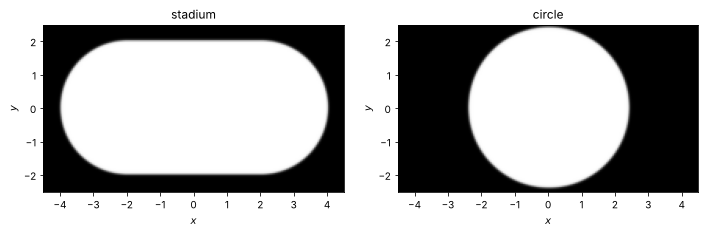

In [2]:
a, R = 2.0, 2.0
size = ((-4.5, 4.5), (-2.5, 2.5))
N = (192, 108)
stadium = so.StadiumPotential2d(a, R, V0=400.0, w=0.04)
circle = so.StadiumPotential2d(0.0, 2.4, V0=400.0, w=0.04, x0=0.0)

grid = so.Grid2d(size, N, stadium, so.Gaussian2d(0.0, 0.0, 0.4))
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
for ax, pot, title in zip(axs, [stadium, circle], ["stadium", "circle"]):
    ax.imshow(np.real(pot.V((grid.X, grid.Y), 0)).T, origin="lower", extent=grid.extent, cmap="Greys")
    ax.set(title=title, xlabel="$x$", ylabel="$y$")
plt.tight_layout()
print(f"dx = {grid.dx:.3f}, maximum kinetic energy on the grid: {grid.k_squared.max()/2:.0f}")

## Dynamics

The same Gaussian wavepacket is launched in both billiards, off center and at an angle. In the
circle the packet keeps circulating along the wall; in the stadium it is quickly smeared over the
whole area. (Pass `mode="phase"` to `animate2d` to see the phase of $\psi$ as color.)

In [3]:
k = 8.0
psi0 = so.Gaussian2d(x0=-1.0, y0=0.5, sigma_x=0.4, px=k*np.cos(0.6), py=k*np.sin(0.6))
dt = 0.004

anims = {}
for name, pot in [("stadium", stadium), ("circle", circle)]:
    g = so.Grid2d(size, N, pot, psi0)
    anims[name] = so.animate2d(g, so.SplitOperator(), dt, n_frames=32, steps_per_frame=40,
                               potential_levels=[200.0], vmax=0.3)
HTML(anims["stadium"].to_jshtml())

In [4]:
HTML(anims["circle"].to_jshtml())

## Spectrum from the autocorrelation function

As in 1d, the Fourier transform of $C(t) = \langle\psi_0|\psi(t)\rangle$ shows the eigenenergies, weighted
by the overlap of each eigenstate with the initial packet. We now launch the packet at the center along
the long axis. Classically, this is the *horizontal bouncing orbit*, a periodic but unstable orbit
of length $L = 2(2a + 2R)$.

The mean level spacing is $\Delta E = 2\pi/A$ for a billiard of area $A$ (Weyl's law); resolving
single levels needs a propagation time well beyond $2\pi/\Delta E = A$.

area A = 28.6, mean level spacing = 0.220, t_max = 120.0


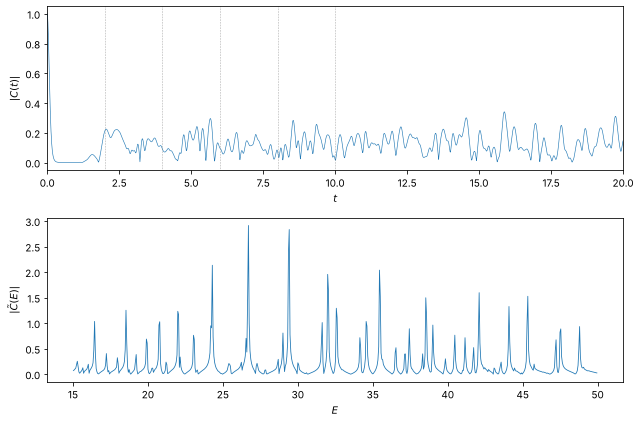

In [5]:
psi0 = so.Gaussian2d(0.0, 0.0, 0.4, px=k)
grid = so.Grid2d(size, N, stadium, psi0)
prop = so.SplitOperator()
area = 4*a*R + np.pi*R**2
t_max = 120.0
n_steps = int(t_max/dt)
print(f"area A = {area:.1f}, mean level spacing = {2*np.pi/area:.3f}, t_max = {t_max}")

phi0 = grid.psi.copy()
C = np.empty(n_steps, dtype=complex)
for i in range(n_steps):
    C[i] = np.sum(np.conj(phi0)*grid.psi)*grid.dV
    prop.step(grid, dt)

window = np.hanning(2*n_steps)[n_steps:]
E = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(n_steps, dt))
spectrum = np.abs(np.fft.fftshift(np.fft.ifft(C*window)))*n_steps*dt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6))
ax1.plot(np.arange(n_steps)*dt, np.abs(C), lw=0.6)
ax1.set(xlim=(0, 20), xlabel="$t$", ylabel="$|C(t)|$")
for n in range(1, 6):
    ax1.axvline(n*2*(2*a + 2*R)/k, c="gray", lw=0.6, ls=":")
sel = (E > 15) & (E < 50)
ax2.plot(E[sel], spectrum[sel], lw=0.8)
ax2.set(xlabel="$E$", ylabel=r"$|\tilde C(E)|$")
plt.tight_layout()

The dotted lines in the upper panel mark multiples of the orbit's period $T = L/k$: the packet partially
returns after each round trip, until chaos spreads it out. Correspondingly, the spectrum is modulated
with the period $\Delta E = 2\pi k/L$: levels near these energies overlap strongly with the packet.

## Scarred eigenstates

Energy filtering at the strongest peaks yields the corresponding eigenstates. Many of them show an
enhanced density along the horizontal orbit: a *scar*. Random-wave models of chaotic eigenstates
would predict a featureless speckle pattern instead.

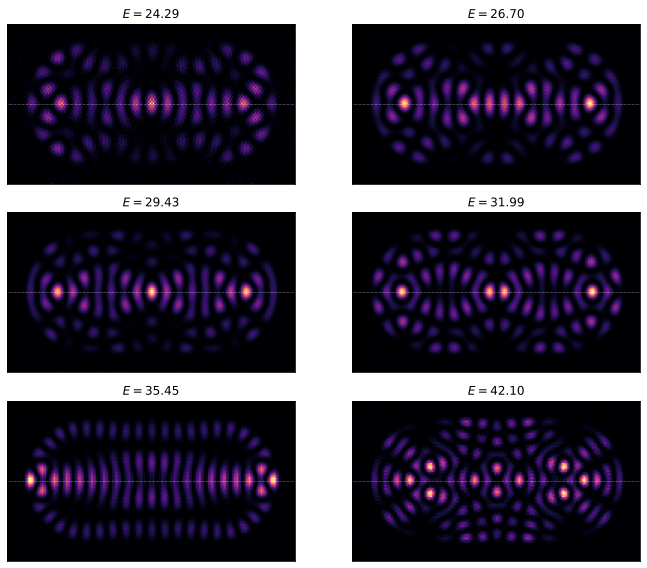

In [6]:
from scipy.signal import find_peaks

peaks, _ = find_peaks(np.where(sel, spectrum, 0.0), distance=int(0.5/(E[1] - E[0])))
strongest = np.sort(peaks[np.argsort(spectrum[peaks])[-6:]])
energies = E[strongest]

grid = so.Grid2d(size, N, stadium, psi0)
filt = so.analyzers.EigenstateFilter(energies, t_max)
filt.add_data(grid.psi, grid.t, dt)
prop.propagate(grid, dt, n_steps, callback=lambda g: filt.add_data(g.psi, g.t, dt))

fig, axs = plt.subplots(3, 2, figsize=(10, 8))
for ax, phi, e in zip(axs.flat, filt.eigenstates(grid.dV), energies):
    ax.imshow(np.abs(phi.T)**2, origin="lower", extent=grid.extent, cmap="magma")
    ax.axhline(0.0, c="white", lw=0.5, ls=":")
    ax.set_title(f"$E = {e:.2f}$")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

The dotted line marks the horizontal orbit. Peaks that are not well separated from a neighbor give
mixtures of two states; a longer propagation time sharpens them.